In [138]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [139]:
# ------------------ Paths --------------------------
caravan_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/ensemble_metrics/total_precipitation_sum_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
camels_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/ensemble_metrics/camels_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
caravan_peak_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/4_paper/4_precip_analysis/peak_metrics/530_united_states/peak_metrics.csv")

caravan_attributes_dir = Path("/inputs/data_updated_2/attributes/attributes_caravan.csv")
caravan_attributes_2_dir = Path("/inputs/data_updated_2/attributes/attributes_other.csv")
caravan_attributes_3_dir = Path("/inputs/data_updated_2/attributes/attributes_hydroatlas.csv")

caravan_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/total_precipitation_sum_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
camels_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/camels_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
chirps_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/chirps_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
mswep_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/mswep_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")

In [140]:
attributes = pd.read_csv(caravan_attributes_dir)
attributes.head()
# len(attributes)

,gauge_id,aridity_ERA5_LAND,aridity_FAO_PM,frac_snow,high_prec_dur,high_prec_freq,low_prec_dur,low_prec_freq,moisture_index_ERA5_LAND,moisture_index_FAO_PM,p_mean,pet_mean_ERA5_LAND,pet_mean_FAO_PM,seasonality_ERA5_LAND,seasonality_FAO_PM
0,camels_01013500,3.763929,0.492557,0.374538,1.105263,0.047433,2.835099,0.586037,-0.598445,0.537406,3.175454,11.952184,1.564091,0.849594,0.972252
1,camels_01022500,4.539418,0.580916,0.335440,1.083770,0.056674,3.238029,0.638741,-0.716118,0.409718,3.203837,14.543556,1.861159,0.458492,1.187054
2,camels_01030500,4.263635,0.532879,0.316130,1.093123,0.052225,3.029760,0.613210,-0.667997,0.471618,3.184069,13.575707,1.696722,0.632035,1.119152
3,camels_01031500,3.947586,0.510585,0.306273,1.093185,0.053799,3.149326,0.623614,-0.646806,0.495480,3.289056,12.983833,1.679343,0.667906,1.097448
4,camels_01047000,3.694839,0.501584,0.299063,1.100430,0.052498,3.239731,0.626215,-0.628010,0.512243,3.275610,12.102852,1.642993,0.679129,1.047740


In [141]:
attributes_2 = pd.read_csv(caravan_attributes_2_dir)
attributes_2.head()
# len(attributes_2)

,gauge_id,gauge_name,country,gauge_lat,gauge_lon,area
0,camels_01013500,"Fish River near Fort Kent, Maine",United States of America,47.23739,-68.58264,2297.683155
1,camels_01022500,"Narraguagus River at Cherryfield, Maine",United States of America,44.60797,-67.93524,619.102595
2,camels_01030500,"Mattawamkeag River near Mattawamkeag, Maine",United States of America,45.50097,-68.30596,3666.943011
3,camels_01031500,"Piscataquis River near Dover-Foxcroft, Maine",United States of America,45.17501,-69.31470,764.824149
4,camels_01047000,"Carrabassett River near North Anson, Maine",United States of America,44.86920,-69.95510,902.895076


In [142]:
attributes_3 = pd.read_csv(caravan_attributes_3_dir)
attributes_3.head()
# len(attributes_3)

,gauge_id,sgr_dk_sav,glc_pc_s06,glc_pc_s07,nli_ix_sav,glc_pc_s04,glc_pc_s05,glc_pc_s02,glc_pc_s03,glc_pc_s01,...,dis_m3_pmn,dis_m3_pmx,dis_m3_pyr,lkv_mc_usu,rev_mc_usu,ria_ha_usu,riv_tc_usu,pop_ct_usu,dor_pc_pva,area_fraction_used_for_aggregation
0,camels_01013500,62.866664,83.686013,0.0,224.825073,1.155256,0.0,3.452859,0.0,0.0,...,29.056,96.345,43.627,1626,0,574.366,3455.373,3.768,0,0.990556
1,camels_01022500,36.966994,59.203650,0.0,64.114413,0.000000,0.0,37.562392,0.0,0.0,...,10.668,22.863,14.735,33,0,127.307,536.621,0.397,0,0.977213
2,camels_01030500,35.720051,80.191823,0.0,132.317749,0.127213,0.0,14.337860,0.0,0.0,...,62.116,139.913,79.962,626,116,994.800,7078.501,7.386,46,0.990762
3,camels_01031500,81.916647,28.886132,0.0,259.835094,0.000000,0.0,69.125573,0.0,0.0,...,15.396,32.990,19.704,88,0,172.797,823.769,3.910,0,0.972291
4,camels_01047000,143.513055,15.083741,0.0,372.303975,0.000000,0.0,83.922247,0.0,0.0,...,13.333,45.706,20.694,37,0,208.190,995.284,3.511,0,0.987281


In [143]:
# for column in attributes_3.columns:
#     print(column)

In [144]:
ensemble_metrics = pd.read_csv(caravan_metrics_dir)
ensemble_metrics.head()
# len(ensemble_metrics)

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01022500,0.749536,1.558084,1.248233,0.867014,0.998797,0.875566,0.953097,-0.043508,3.069363,-6.344704,41.908733,0.272727,0.281250,36.178741
1,camels_01031500,0.800767,2.044064,1.429708,0.847784,0.901590,0.895543,1.050733,0.034540,-8.391373,-16.757488,64.915009,0.272727,0.181818,30.384523
2,camels_01047000,0.761448,2.855816,1.689916,0.752403,0.802424,0.877956,0.914132,-0.060452,-17.735838,-13.208194,18.773703,0.363636,0.270270,35.831432
3,camels_01052500,0.841340,1.954236,1.397940,0.867342,0.897413,0.917528,1.016505,0.010619,-9.976896,-10.814296,46.969646,0.166667,0.315789,33.657455
4,camels_01054200,0.603612,13.159534,3.627607,0.557595,0.617607,0.799534,0.903505,-0.050458,-39.208607,-6.626186,7.239662,0.500000,0.368421,51.915413


In [145]:
ensemble_peak_metrics = pd.read_csv(caravan_peak_metrics_dir)
ensemble_peak_metrics = ensemble_peak_metrics.rename(columns={"basin": "basin_id"})
ensemble_peak_metrics.head()
len(ensemble_peak_metrics)

531

In [146]:
ensemble_camels_metrics = pd.read_csv(camels_metrics_dir)
ensemble_camels_metrics.head()
# len(ensemble_camels_metrics)

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01022500,0.873195,0.788830,0.888161,0.862428,0.898171,0.937404,0.931892,-0.063178,-8.366964,-3.287585,21.083689,0.181818,0.218750,23.027092
1,camels_01031500,0.888100,1.148055,1.071473,0.849362,0.859370,0.946412,0.993412,-0.004485,-13.875319,-9.154499,43.207787,0.181818,0.121212,27.374205
2,camels_01047000,0.875006,1.496363,1.223259,0.856017,0.875586,0.937855,0.962715,-0.026249,-12.341771,-3.645504,-7.947985,0.090909,0.324324,23.634581
3,camels_01052500,0.885470,1.410681,1.187721,0.891121,0.997709,0.944424,1.093598,0.060219,-1.528729,-5.378186,28.173573,0.083333,0.184211,26.958374
4,camels_01054200,0.657618,11.366599,3.371439,0.594510,0.635551,0.836159,0.931040,-0.036060,-36.622028,-4.827666,-7.782070,0.250000,0.210526,44.101734


In [147]:
merged = (
    ensemble_camels_metrics[["basin_id", "NSE"]]
    .merge(
        ensemble_peak_metrics[["basin_id", "peak_timing", "missed_peaks"]], #, "mape_peak"]],
        on="basin_id",
        how="inner",
    )
    .merge(
        attributes[["gauge_id", "frac_snow", "p_mean", "high_prec_dur", "low_prec_dur"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_2[["gauge_id", "area"]],
        on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_3[["gauge_id", "ele_mt_sav"]],
        on="gauge_id",
        how="inner",
    )
    [["basin_id", "NSE", "peak_timing", "missed_peaks", "frac_snow", "p_mean", "high_prec_dur", "low_prec_dur", "area", "ele_mt_sav"]]
)

merged.head()

,basin_id,NSE,peak_timing,missed_peaks,frac_snow,p_mean,high_prec_dur,low_prec_dur,area,ele_mt_sav
0,camels_01022500,0.873195,0.800000,0.629630,0.335440,3.203837,1.083770,3.238029,619.102595,103.274219
1,camels_01031500,0.888100,0.600000,0.446429,0.306273,3.289056,1.093185,3.149326,764.824149,303.634479
2,camels_01047000,0.875006,0.666667,0.464286,0.299063,3.275610,1.100430,3.239731,902.895076,378.958111
3,camels_01052500,0.885470,0.254545,0.807018,0.368406,3.402069,1.078040,2.515905,395.444910,644.379447
4,camels_01054200,0.657618,0.321429,0.500000,0.374272,3.664167,1.104073,2.938824,180.835783,626.000000


In [148]:
len(merged)

530

What I want to do is to comapre teh ag between a precipitation peak and the corresponding streamflow peak for all the US basins. This is to see if there is a relationship between the lag and the fraction of snow. 
In the peak metrics I am comparing camels_precipitation to the observed streamflow.

In [161]:
snow_bins = [0, 0.1, 0.15, 0.25, 0.4, float("inf")]
snow_labels = ["> 0 - 0.1", "0.1 - 0.15", "0.15 - 0.25", "0.25 - 0.4", "> 0.4"]

merged["frac_snow_group"] = pd.NA

zero_snow = merged["frac_snow"].eq(0)
positive_snow = merged["frac_snow"].gt(0)

merged.loc[zero_snow, "frac_snow_group"] = "0"
merged.loc[positive_snow, "frac_snow_group"] = pd.cut(
    merged.loc[positive_snow, "frac_snow"],
    bins=snow_bins,
    labels=snow_labels,
    right=False,
)

basin_counts = (
    merged["frac_snow_group"]
    .value_counts()
    .reindex(["0"] + snow_labels, fill_value=0)
    .rename("basin_count")
    .to_frame()
)

basin_counts

,basin_count
frac_snow_group,
0,236
> 0 - 0.1,47
0.1 - 0.15,34
0.15 - 0.25,90
0.25 - 0.4,62
> 0.4,61


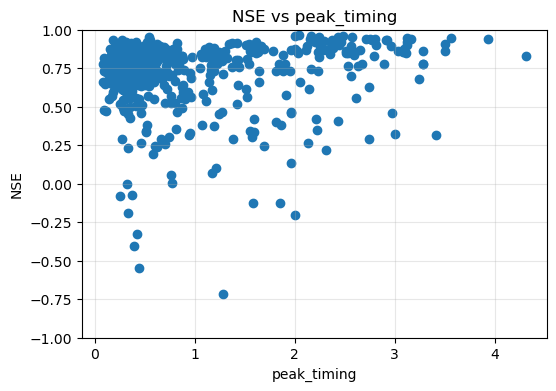

In [162]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["peak_timing"], #camels_precip vs streamlow (lag in timing)
    merged["NSE"],
)
plt.xlabel("peak_timing")
plt.ylabel("NSE")
plt.title("NSE vs peak_timing")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.show()

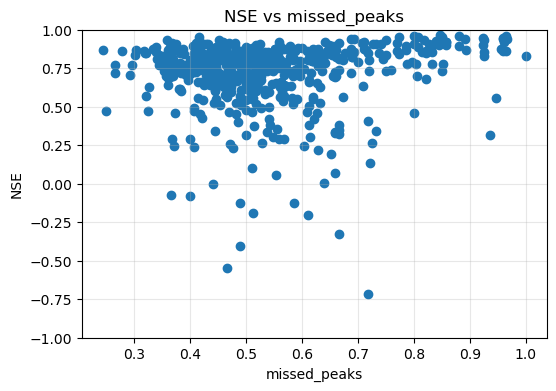

In [163]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["missed_peaks"],
    merged["NSE"],
)
plt.xlabel("missed_peaks")
plt.ylabel("NSE")
plt.title("NSE vs missed_peaks")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.show()

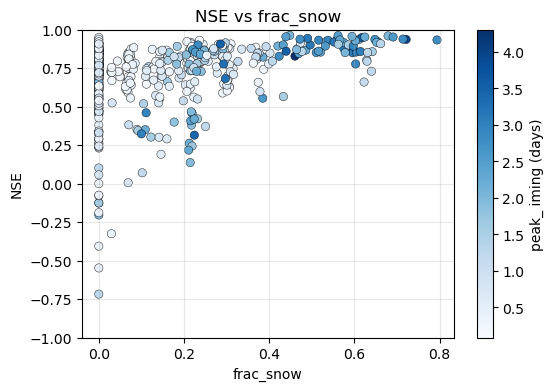

In [164]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["frac_snow"],
    merged["NSE"],
    c=merged["peak_timing"], #camels_precip vs streamlow (lag in timing)
    cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs frac_snow")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="peak_ iming (days)")
plt.show()

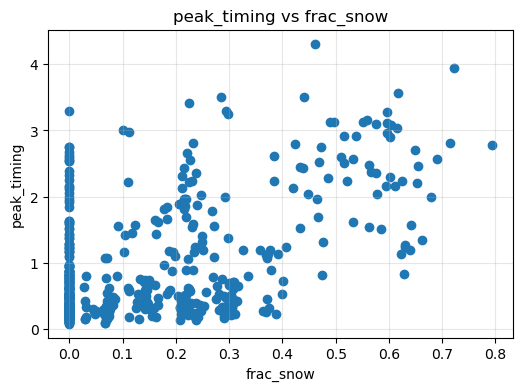

In [156]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["frac_snow"],
    merged["peak_timing"],
)
plt.xlabel("frac_snow")
plt.ylabel("peak_timing")
plt.title("peak_timing vs frac_snow")
plt.grid(True, alpha=0.3)
# plt.ylim(bottom=-1, top=1)
plt.show()

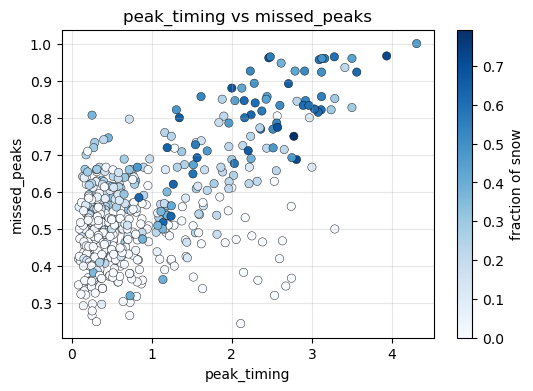

In [165]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["peak_timing"], 
    merged["missed_peaks"],
    c=merged["frac_snow"],
    cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("peak_timing")
plt.ylabel("missed_peaks")
plt.title("peak_timing vs missed_peaks")
plt.grid(True, alpha=0.3)
# plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="fraction of snow")
plt.show()

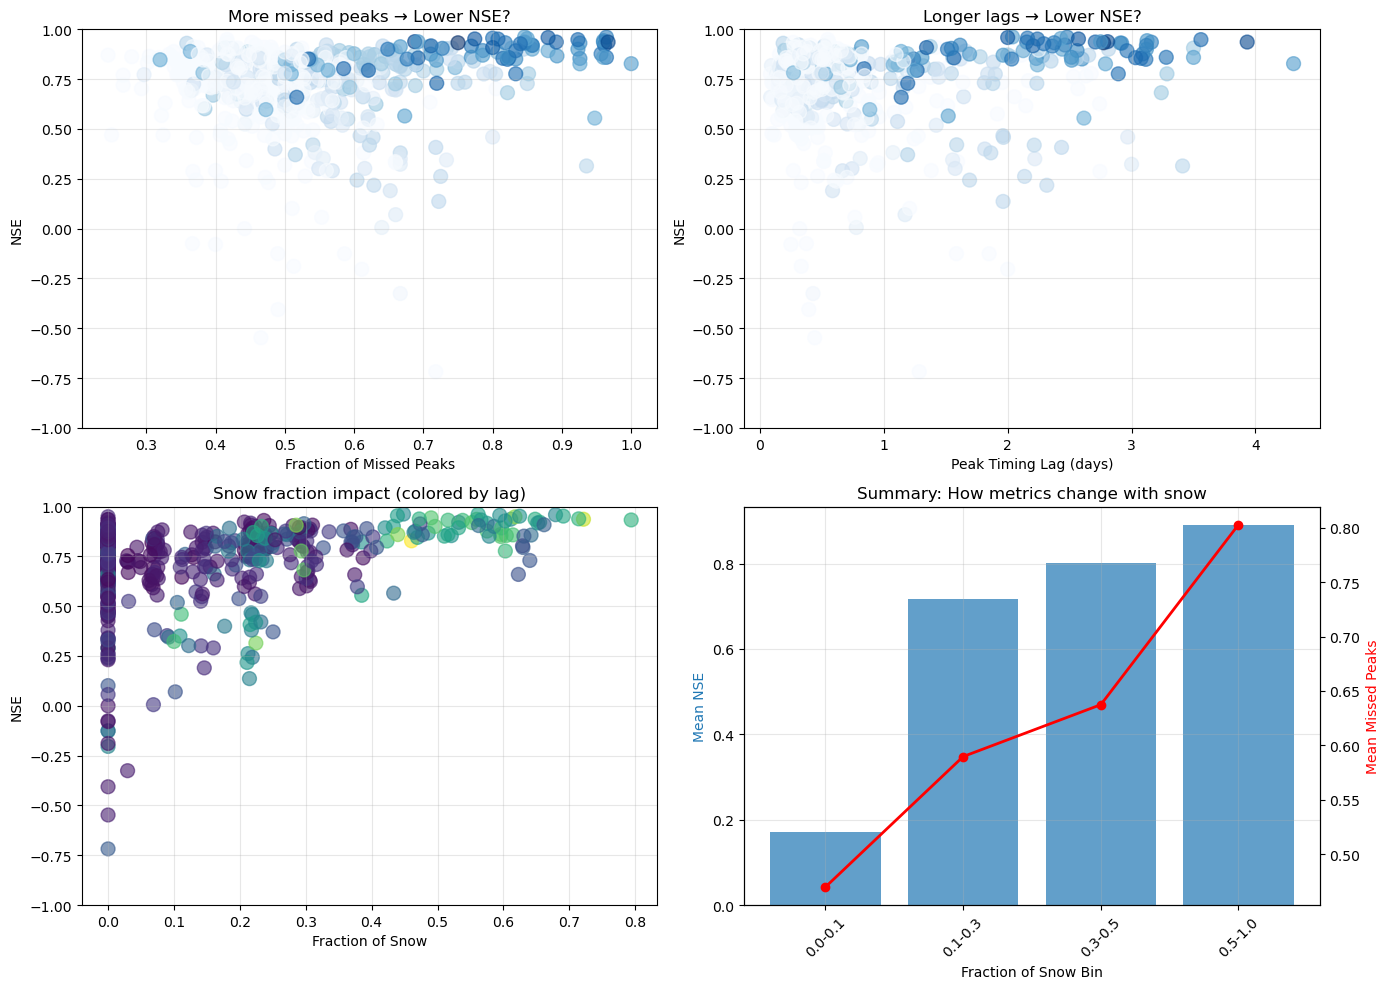

In [166]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: missed_peaks vs NSE
axes[0,0].scatter(merged['missed_peaks'], merged['NSE'], 
                  c=merged['frac_snow'], s=100, alpha=0.6, cmap='Blues')
axes[0,0].set_xlabel('Fraction of Missed Peaks')
axes[0,0].set_ylabel('NSE')
axes[0,0].set_title('More missed peaks → Lower NSE?')
axes[0,0].grid(True, alpha=0.3)
axes[0,0].set_ylim(-1, 1)

# Top-right: peak_timing vs NSE
axes[0,1].scatter(merged['peak_timing'], merged['NSE'], 
                  c=merged['frac_snow'], s=100, alpha=0.6, cmap='Blues')
axes[0,1].set_xlabel('Peak Timing Lag (days)')
axes[0,1].set_ylabel('NSE')
axes[0,1].set_title('Longer lags → Lower NSE?')
axes[0,1].grid(True, alpha=0.3)
axes[0,1].set_ylim(-1, 1)

# Bottom-left: frac_snow vs NSE (your original)
axes[1,0].scatter(merged['frac_snow'], merged['NSE'], 
                  c=merged['peak_timing'], s=100, alpha=0.6, cmap='viridis')
axes[1,0].set_xlabel('Fraction of Snow')
axes[1,0].set_ylabel('NSE')
axes[1,0].set_title('Snow fraction impact (colored by lag)')
axes[1,0].grid(True, alpha=0.3)
axes[1,0].set_ylim(-1, 1)

# Bottom-right: Summary statistics
snow_bins = [0, 0.1, 0.3, 0.5, 1.0]
summary_data = []
for i in range(len(snow_bins)-1):
    mask = (merged['frac_snow'] >= snow_bins[i]) & (merged['frac_snow'] < snow_bins[i+1])
    summary_data.append({
        'bin': f'{snow_bins[i]:.1f}-{snow_bins[i+1]:.1f}',
        'mean_NSE': merged[mask]['NSE'].mean(),
        'mean_missed': merged[mask]['missed_peaks'].mean(),
        'mean_lag': merged[mask]['peak_timing'].mean()
    })

summary_df = pd.DataFrame(summary_data)
x_pos = range(len(summary_df))
axes[1,1].bar(x_pos, summary_df['mean_NSE'], alpha=0.7, label='Mean NSE')
ax2 = axes[1,1].twinx()
ax2.plot(x_pos, summary_df['mean_missed'], 'r-o', linewidth=2, label='Mean Missed %')
axes[1,1].set_xlabel('Fraction of Snow Bin')
axes[1,1].set_ylabel('Mean NSE', color='C0')
ax2.set_ylabel('Mean Missed Peaks', color='red')
axes[1,1].set_xticks(x_pos)
axes[1,1].set_xticklabels(summary_df['bin'], rotation=45)
axes[1,1].set_title('Summary: How metrics change with snow')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [167]:
# How strongly are precip peaks linked to streamflow peaks?
# Low = timing doesn't matter much (snow-dominated behavior)
# High = timing is critical (rain-dominated behavior)

merged['timing_importance'] = 1 - merged['missed_peaks']
# OR: use correlation between precip and streamflow as proxy

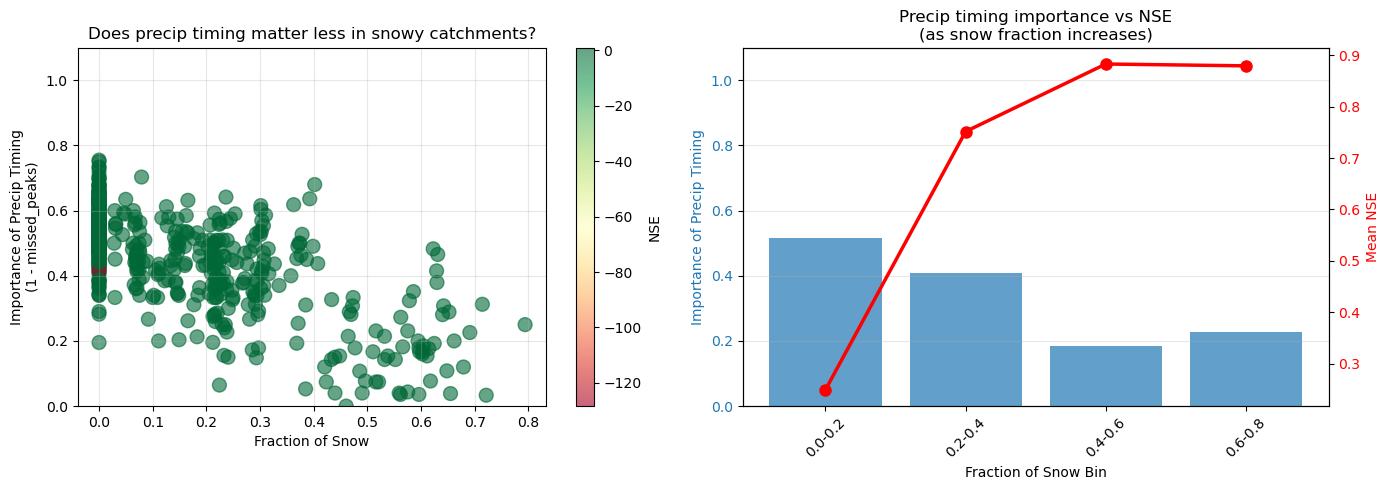

In [160]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LEFT: Importance of precip timing vs snow fraction
axes[0].scatter(merged['frac_snow'], 
               1 - merged['missed_peaks'],  # ← High value = timing matters
               c=merged['NSE'], 
               s=100, alpha=0.6, cmap='RdYlGn')
axes[0].set_xlabel('Fraction of Snow')
axes[0].set_ylabel('Importance of Precip Timing\n(1 - missed_peaks)')
axes[0].set_title('Does precip timing matter less in snowy catchments?')
cbar = plt.colorbar(axes[0].collections[0], ax=axes[0])
cbar.set_label('NSE')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.1])

# RIGHT: Binned view
snow_bins = np.linspace(0, 1, 6)
timing_importance_by_bin = []
nse_by_bin = []
labels = []

for i in range(len(snow_bins)-1):
    mask = (merged['frac_snow'] >= snow_bins[i]) & (merged['frac_snow'] < snow_bins[i+1])
    if mask.sum() > 0:
        timing_importance_by_bin.append((1 - merged[mask]['missed_peaks']).mean())
        nse_by_bin.append(merged[mask]['NSE'].mean())
        labels.append(f'{snow_bins[i]:.1f}-{snow_bins[i+1]:.1f}')

x_pos = range(len(labels))
ax1 = axes[1]
ax1.bar(x_pos, timing_importance_by_bin, alpha=0.7, label='Importance of Precip Timing')
ax1.set_xlabel('Fraction of Snow Bin')
ax1.set_ylabel('Importance of Precip Timing', color='C0')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels, rotation=45)
ax1.set_ylim([0, 1.1])
ax1.tick_params(axis='y', labelcolor='C0')

ax2 = ax1.twinx()
ax2.plot(x_pos, nse_by_bin, 'r-o', linewidth=2.5, markersize=8, label='Mean NSE')
ax2.set_ylabel('Mean NSE', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_title('Precip timing importance vs NSE\n(as snow fraction increases)')
ax1.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()